# 01. Thu thập và tìm hiểu bộ dữ liệu

Notebook trình bày chủ đề, nguồn gốc, giấy phép, phương pháp tạo dữ liệu và lý do nhóm lựa chọn bộ dữ liệu **Diabetes Risk Prediction**. Thông tin nguồn được kiểm tra ngày **28/10/2026**; các thống kê mô tả được tính từ tệp `data/raw/diabetes_risk.csv` trong dự án.

## 1. Subject — Chủ đề và bối cảnh thực tế

Bộ dữ liệu mô phỏng bài toán **phân loại nguy cơ đái tháo đường** dựa trên đặc điểm nhân khẩu học, tiền sử gia đình, lối sống và các chỉ số sức khỏe trong bối cảnh Ấn Độ. Mục tiêu phân tích là sử dụng các thuộc tính này để dự đoán một hồ sơ thuộc nhóm nguy cơ thấp, trung bình hay cao.

Theo metadata Kaggle [1], đây là **dữ liệu tổng hợp (synthetic)**, phục vụ học tập và thử nghiệm mô hình. Mỗi dòng biểu diễn một cá nhân được mô phỏng bằng chương trình. Các mức nguy cơ là nhãn do thuật toán tạo ra, chưa được xác nhận là kết quả chẩn đoán lâm sàng.

Tệp CSV của dự án có **15.000 dòng và 19 cột**, gồm một mã định danh, 17 thuộc tính mô tả và một biến đích. Tuổi quan sát nằm trong khoảng **18–80**, với địa điểm thuộc **18 thành phố của Ấn Độ**.

| Nhóm thông tin | Các thuộc tính |
| --- | --- |
| Định danh | `patient_id` |
| Nhân khẩu học và kinh tế | `age`, `gender`, `city`, `income_bracket` |
| Tiền sử gia đình | `family_history_diabetes` |
| Lối sống | `physical_activity_level`, `diet_type`, `smoking_status`, `alcohol_consumption`, `hours_sleep_per_night`, `stress_level` |
| Chỉ số cơ thể và sức khỏe | `bmi`, `fasting_blood_sugar`, `hba1c_level`, `blood_pressure_systolic`, `blood_pressure_diastolic`, `waist_circumference_cm` |
| Biến đích | `diabetes_risk`, gồm `Low`, `Moderate`, `High` |

## 2. Source — Nguồn dữ liệu

| Nội dung | Thông tin |
| --- | --- |
| Tên bộ dữ liệu | **Diabetes Risk Prediction** |
| Nền tảng | Kaggle |
| Trang công bố | Kaggle [2] |
| Tác giả/người công bố | **Mansi Aggarwal**, tài khoản `mansiaggarwal88` |
| Tổ chức gốc | Nguồn không công bố tổ chức y tế hoặc đơn vị khảo sát cung cấp dữ liệu thực |
| Ngày công bố lần đầu | **13/08/2026** |
| Phiên bản được đối chiếu | **Version 1**, ghi chú “Initial release” |
| Ngày cập nhật phiên bản | **13/08/2026** |
| Ngày kiểm tra nguồn | **28/10/2026** |
| Tệp trong dự án | `data/raw/diabetes_risk.csv` |

Tên tác giả, phiên bản và ngày phát hành được xác minh qua metadata API của Kaggle [1]. Trường `versions[0].creationDate` ghi nhận thời điểm phát hành đầu tiên là `2026-08-13T15:38:56.197Z`.

Gói tải phiên bản 1 [3] gồm `diabetes_risk.csv` và mã sinh dữ liệu `generate_dataset.py`. Nội dung CSV trong dự án khớp với bản nguồn sau khi chuẩn hóa ký tự xuống dòng và bỏ ký tự xuống dòng cuối tệp.

Dự án chưa lưu thông tin ngày tải dữ liệu ban đầu. Ngày 28/10/2026 là ngày kiểm tra nguồn, không được dùng thay cho ngày tải.

## 3. License — Giấy phép và yêu cầu trích dẫn

Bộ dữ liệu được tác giả khai báo trên Kaggle [1] theo giấy phép **CC0: Public Domain**. Theo CC0 1.0 Universal của Creative Commons [4], người dùng có thể sao chép, chỉnh sửa và phân phối dữ liệu, kể cả cho mục đích thương mại, trong phạm vi quyền tác giả được từ bỏ theo CC0.

**CC0 không bắt buộc ghi công.** Tuy nhiên, để bảo đảm minh bạch học thuật và giúp người đọc truy xuất đúng bộ dữ liệu, nhóm vẫn ghi tên tác giả, tên dữ liệu, phiên bản, đường dẫn và ngày truy cập. Nguồn được kiểm tra chưa cung cấp mẫu trích dẫn riêng; nhóm sử dụng mẫu sau:

> Aggarwal, M. (2026). *Diabetes Risk Prediction* (Version 1) [Bộ dữ liệu tổng hợp]. Kaggle [2]. Truy cập ngày 28/10/2026. CC0 1.0 Universal.

Trong báo cáo, nhóm cũng mô tả các bước làm sạch và biến đổi để người đọc phân biệt được dữ liệu gốc với dữ liệu đã xử lý.

## 4. Collection method — Phương pháp tạo và tiếp nhận dữ liệu

### Phương pháp tạo dữ liệu

Theo `generate_dataset.py` trong gói dữ liệu gốc [3], tác giả sử dụng **Python với NumPy, pandas và SciPy** để sinh dữ liệu. Cấu hình mặc định là **15.000 hồ sơ**, với **seed = 42**. Nguồn không mô tả quy trình khảo sát, thu từ cảm biến, trích xuất bệnh án hoặc scraping dữ liệu bệnh nhân.

Chương trình lấy mẫu các đặc điểm cá nhân theo phân phối định sẵn, sau đó tạo các thuộc tính liên quan bằng công thức kèm nhiễu. Chẳng hạn, thu nhập liên quan đến nhóm thành phố; vận động liên quan đến tuổi và thu nhập; vòng eo liên quan đến BMI; HbA1c liên quan đến đường huyết lúc đói. Chương trình còn mô phỏng xu hướng làm tròn giờ ngủ và huyết áp.

Để tạo nhãn, tác giả tính một điểm logistic từ tuổi, BMI, tiền sử gia đình, HbA1c, đường huyết lúc đói và các thành phần tương tác, rồi thêm nhiễu. Điểm được chia tại **phân vị 60 và 85** để tạo ba nhóm `Low`, `Moderate`, `High`, với tỷ lệ thiết kế **60%–25%–15%**. Các mốc này là ngưỡng chia nhãn trong mẫu mô phỏng, không phải ngưỡng chẩn đoán y khoa.

Nhóm sử dụng dữ liệu thứ cấp được phân phối trên Kaggle, với bản CSV lưu tại `data/raw/diabetes_risk.csv` cho các bước phân tích tiếp theo.

### Quần thể và khoảng thời gian

Dữ liệu mô phỏng người trưởng thành thuộc 18 thành phố tại Ấn Độ. Mã sinh đặt giới hạn tuổi **18–95**, còn khoảng tuổi thực sự xuất hiện trong CSV là **18–80**. Các hồ sơ được lấy mẫu bằng chương trình theo trọng số do tác giả chọn; không có khung chọn mẫu từ dân số thực.

Bộ dữ liệu không có ngày khám, ngày đo hoặc lịch sử theo dõi. Vì vậy, **không có khoảng thời gian thu thập thực địa để báo cáo**. Ngày 13/08/2026 chỉ là ngày công bố dữ liệu.

### Cách tạo giá trị thiếu

Mã nguồn chủ động xóa một số giá trị để phục vụ thực hành xử lý dữ liệu thiếu:

- **`smoking_status` và `income_bracket`:** xóa độc lập với xác suất 3% cho mỗi cột, phù hợp với cơ chế **MCAR** — thiếu hoàn toàn ngẫu nhiên.
- **`alcohol_consumption`:** xác suất thiếu được tính bằng `0.1 + 0.3 × (gender == "Female") + 0.2 × (age > 60)`, nên thay đổi theo giới tính và tuổi.

Tác giả gọi cơ chế thiếu ở cột rượu bia là **MNAR** trong chú thích mã. Tuy nhiên, công thức thực thi chỉ phụ thuộc vào tuổi và giới tính đã quan sát, không phụ thuộc vào giá trị uống rượu bị che đi. Vì vậy, **cơ chế được cài đặt phù hợp với MAR** — thiếu ngẫu nhiên có điều kiện theo các biến quan sát. Nhóm ghi rõ sự khác biệt này khi diễn giải dữ liệu.

Trong CSV của dự án, cột rượu bia có **3.788 ô thiếu (25,25%)**, hút thuốc có **472 ô thiếu (3,15%)** và thu nhập có **463 ô thiếu (3,09%)**. Không nên thay giá trị rượu bia bị thiếu bằng `Never`, vì thiếu thông tin không đồng nghĩa với không uống rượu.

### Hạn chế và thiên lệch

| Hạn chế | Ảnh hưởng đến phân tích |
| --- | --- |
| Dữ liệu và quan hệ giữa các biến được tạo bằng công thức | Mô hình có thể học lại quy luật sinh dữ liệu; tương quan quan sát được không đủ để kết luận nhân quả |
| Phân phối dân số và thành phố do tác giả đặt | Mẫu không chứng minh tính đại diện cho toàn bộ Ấn Độ hoặc dân số Việt Nam |
| Nhãn được chia theo phân vị | Tỷ lệ các lớp phản ánh thiết kế của tác giả, không phản ánh tỷ lệ nguy cơ trong cộng đồng |
| Giá trị thiếu phụ thuộc nhóm tuổi và giới tính | Xóa mọi dòng thiếu có thể làm thay đổi thành phần mẫu và gây lệch kết quả |
| Nhãn được tạo từ cả các chỉ số xét nghiệm | Nếu hướng đến sàng lọc trước xét nghiệm, cần đánh giá thêm mô hình khi loại các chỉ số xét nghiệm |
| Không có kết cục bệnh thực tế hoặc theo dõi theo thời gian | Chưa thể xác nhận khả năng dự đoán mắc bệnh trong tương lai hoặc sử dụng cho quyết định lâm sàng |

Khi xây dựng mô hình, nhóm loại `patient_id` khỏi đặc trưng dự đoán và đánh giá từng lớp nguy cơ để tránh phụ thuộc vào accuracy khi các lớp có quy mô khác nhau.

## 5. Motivation — Động lực nhóm lựa chọn

Nhóm lựa chọn bộ dữ liệu này vì bài toán phân loại nguy cơ đái tháo đường có bối cảnh rõ ràng và phù hợp với mục tiêu thực hành của học phần. Các thuộc tính trải rộng từ nhân khẩu học, lối sống đến chỉ số sức khỏe, giúp nhóm đặt câu hỏi phân tích và tìm hiểu vai trò của nhiều nhóm đặc trưng trong cùng một bài toán.

Với 15.000 hồ sơ và sự kết hợp giữa biến số, biến phân loại và giá trị thiếu, dữ liệu đủ để nhóm thực hành các bước đọc dữ liệu, kiểm tra chất lượng, khám phá, tiền xử lý, tạo đặc trưng và so sánh mô hình. Ba mức nguy cơ có tỷ lệ khác nhau cũng tạo điều kiện để nhóm tìm hiểu cách đánh giá mô hình phân loại đa lớp.

Một lý do khác là bộ dữ liệu có nguồn công khai, giấy phép rõ ràng và mã sinh đi kèm. Nhờ đó, nhóm có thể kiểm tra cách hình thành các thuộc tính, giải thích cơ chế dữ liệu thiếu và nhận diện giới hạn khi diễn giải kết quả.

Thông qua bộ dữ liệu này, nhóm hướng đến xây dựng một quy trình phân tích **có thể tái lập và giải thích được**, đồng thời rèn luyện cách báo cáo trung thực về nguồn gốc, thiên lệch và phạm vi sử dụng dữ liệu. Kết quả của dự án phục vụ mục tiêu học tập và thử nghiệm mô hình.

## Kiểm chứng thông tin từ CSV

Hai ô lệnh dưới đây chỉ đọc tệp gốc để kiểm tra quy mô, phân bố nhãn và số lượng giá trị thiếu. Notebook có thể chạy từ thư mục gốc dự án hoặc thư mục `notebooks/`; không cần tải lại dữ liệu từ mạng.

In [1]:
from pathlib import Path
import hashlib
import pandas as pd

candidates = [
    Path.cwd() / "data" / "raw" / "diabetes_risk.csv",
    Path.cwd().parent / "data" / "raw" / "diabetes_risk.csv",
]
data_path = next((path for path in candidates if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError(
        "Không tìm thấy data/raw/diabetes_risk.csv. "
        "Hãy chạy notebook từ thư mục gốc dự án hoặc notebooks/."
    )

df = pd.read_csv(data_path)
print(f"Số dòng: {df.shape[0]:,}; số cột: {df.shape[1]}")
print(f"Khoảng tuổi quan sát: {df['age'].min()}–{df['age'].max()}")
print(f"Số thành phố: {df['city'].nunique()}")
print(f"patient_id duy nhất: {df['patient_id'].is_unique}")
print(f"SHA-256 của tệp: {hashlib.sha256(data_path.read_bytes()).hexdigest()}")

Số dòng: 15,000; số cột: 19
Khoảng tuổi quan sát: 18–80
Số thành phố: 18
patient_id duy nhất: True
SHA-256 của tệp: 1d4ea5e5dfb63ce2622a578736e6a31a330731a7daa8fc93c3987d7c7c119220


In [2]:
risk_counts = df["diabetes_risk"].value_counts().reindex(
    ["Low", "Moderate", "High"], fill_value=0
)
risk_summary = risk_counts.rename_axis("diabetes_risk").to_frame("so_ho_so")
risk_summary["ty_le_phan_tram"] = (risk_counts / len(df) * 100).round(2)
print("PHÂN BỐ NHÃN")
print(risk_summary.to_string())

missing_counts = df.isna().sum()
missing_summary = (
    missing_counts[missing_counts > 0]
    .rename_axis("cot")
    .to_frame("so_o_thieu")
)
missing_summary["ty_le_phan_tram"] = (
    missing_summary["so_o_thieu"] / len(df) * 100
).round(2)
print("\nDỮ LIỆU THIẾU")
print(missing_summary.to_string())

PHÂN BỐ NHÃN
               so_ho_so  ty_le_phan_tram
diabetes_risk                           
Low                9000             60.0
Moderate           3750             25.0
High               2250             15.0

DỮ LIỆU THIẾU
                     so_o_thieu  ty_le_phan_tram
cot                                             
smoking_status              472             3.15
alcohol_consumption        3788            25.25
income_bracket              463             3.09


## 6. Phân phối, xu hướng trung tâm và độ phân tán

Phần khám phá dưới đây được bổ sung ngày **31/10/2026**, chỉ đọc CSV, không xóa dòng hay sửa giá trị. Phân tích **9 biến số mô tả**; loại `patient_id` vì mã định danh không có ý nghĩa về trung tâm, độ phân tán hay ngoại lai. `age` là số nguyên; `stress_level` là thang điểm thứ bậc 1–10 nên các thống kê số chỉ mang tính mô tả.

Với mỗi biến, báo cáo mean, median, mode (kèm số lần xuất hiện), min/max, Q1/Q3, độ lệch chuẩn mẫu (`ddof=1`), IQR và skewness. Skewness âm/dương gợi ý đuôi trái/phải; quy ước mô tả `|skew| < 0,5` là ít lệch theo chỉ số skew, `0,5–1` là lệch vừa, `> 1` là lệch rõ. Skewness gần 0 chưa đủ chứng minh phân phối đối xứng hoặc chuẩn; cần xem cả histogram. Đây không phải kiểm định phân phối chuẩn. Mode của số đo đã làm tròn có thể phản ánh cách tạo dữ liệu.

In [3]:
import numpy as np
from io import BytesIO
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from IPython.display import Image, display

pd.set_option("display.max_columns", None)


def display_figure(fig):
    # Nhúng PNG trực tiếp để biểu đồ không cần backend giao diện.
    buffer = BytesIO()
    FigureCanvasAgg(fig).print_png(buffer)
    display(Image(data=buffer.getvalue()))

numeric_cols = [
    "age", "bmi", "hours_sleep_per_night", "stress_level",
    "fasting_blood_sugar", "hba1c_level", "blood_pressure_systolic",
    "blood_pressure_diastolic", "waist_circumference_cm",
]
units = {
    "age": "năm", "bmi": "kg/m²", "hours_sleep_per_night": "giờ/đêm",
    "stress_level": "điểm (1–10)", "fasting_blood_sugar": "mg/dL",
    "hba1c_level": "%", "blood_pressure_systolic": "mmHg",
    "blood_pressure_diastolic": "mmHg", "waist_circumference_cm": "cm",
}
# Giá trị không hữu hạn chỉ được bỏ khỏi phép tính, vẫn kiểm tra trên df gốc ở mục 9.
numeric_df = df[numeric_cols].replace([np.inf, -np.inf], np.nan)
summary = numeric_df.describe().T.rename(
    columns={"count": "n", "25%": "Q1", "50%": "median", "75%": "Q3"}
)
summary["IQR"] = summary["Q3"] - summary["Q1"]
summary["skewness"] = numeric_df.skew()
summary["mode"] = [", ".join(map(str, numeric_df[c].mode().tolist())) for c in numeric_cols]
summary["mode_count"] = [numeric_df[c].value_counts().max() for c in numeric_cols]
summary["unit"] = pd.Series(units)
display(summary[[
    "unit", "n", "min", "Q1", "median", "mean", "mode", "mode_count",
    "Q3", "max", "std", "IQR", "skewness",
]].round(3))

,unit,n,min,Q1,median,mean,mode,mode_count,Q3,max,std,IQR,skewness
age,năm,15000.0,18.0,38.0,45.0,44.334,47,626,52.0,80.0,10.384,14.0,-0.331
bmi,kg/m²,15000.0,15.0,20.1,22.7,23.062,21.6,184,25.6,40.8,4.046,5.5,0.522
hours_sleep_per_night,giờ/đêm,15000.0,3.0,6.7,7.0,7.310,7.0,3688,8.0,12.0,1.109,1.3,-0.013
stress_level,điểm (1–10),15000.0,1.0,4.0,6.0,5.941,6,2665,7.0,10.0,2.148,3.0,-0.101
fasting_blood_sugar,mg/dL,15000.0,72.0,145.0,165.0,168.790,164,209,189.0,400.0,38.366,44.0,0.851
hba1c_level,%,15000.0,4.8,6.3,6.8,6.878,6.7,833,7.3,13.4,0.843,1.0,0.878
blood_pressure_systolic,mmHg,15000.0,80.0,130.0,140.0,139.496,140,3044,150.0,200.0,12.661,20.0,-0.009
blood_pressure_diastolic,mmHg,15000.0,50.0,80.0,88.0,86.257,80,3499,90.0,120.0,8.387,10.0,0.045
waist_circumference_cm,cm,15000.0,73.2,92.5,99.3,100.208,96.1,82,106.9,148.2,10.760,14.4,0.482


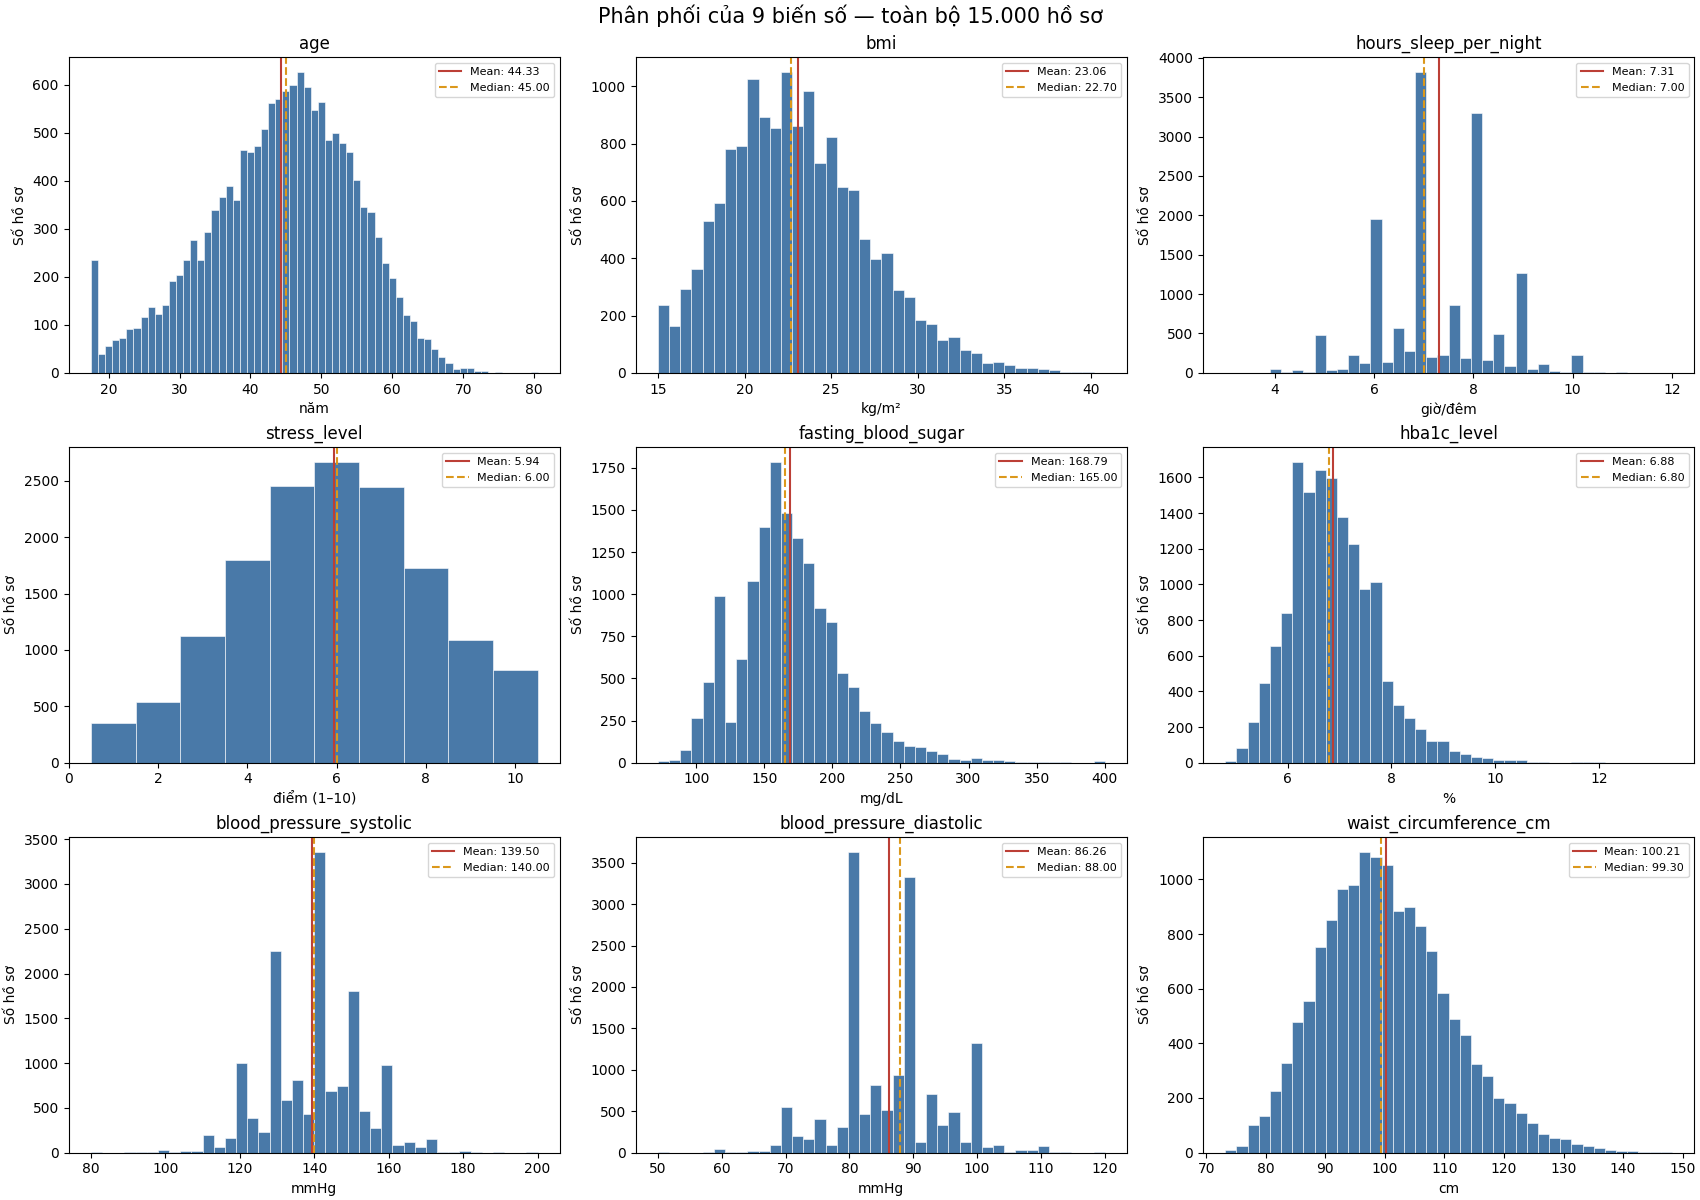

In [4]:
fig = Figure(figsize=(17, 12), layout="constrained")
axes = fig.subplots(3, 3)
for ax, col in zip(axes.flat, numeric_cols):
    s = numeric_df[col].dropna()
    if col == "stress_level":
        bins = np.arange(0.5, 11.5, 1)
    elif col == "age":
        bins = np.arange(s.min() - 0.5, s.max() + 1.5, 1)
    else:
        bins = 40
    ax.hist(s, bins=bins, color="#4979a8", edgecolor="white", linewidth=0.4)
    ax.axvline(s.mean(), color="#bc3f36", linewidth=1.5, label=f"Mean: {s.mean():.2f}")
    ax.axvline(s.median(), color="#db981c", linestyle="--", linewidth=1.5,
               label=f"Median: {s.median():.2f}")
    ax.set(title=col, xlabel=units[col], ylabel="Số hồ sơ")
    ax.legend(fontsize=8)
fig.suptitle("Phân phối của 9 biến số — toàn bộ 15.000 hồ sơ", fontsize=15)
display_figure(fig)

### Nhận xét từ thống kê và histogram

| Biến | Trung tâm và độ phân tán | Hình dáng phân phối và ý nghĩa |
| --- | --- | --- |
| `age` | Mean 44,33; median 45; SD 10,38 năm; IQR 14 năm | Lệch trái nhẹ (skew −0,331); có 234 hồ sơ đúng 18 tuổi, gồm 187 giá trị bị chặn từ dưới 18 và 47 giá trị đã bằng 18 sau làm tròn, trước khi chặn. Không suy ra phân phối tuổi dân số từ mẫu mô phỏng. |
| `bmi` | Mean 23,06 > median 22,70; SD 4,05; IQR 5,50 kg/m² | Lệch phải vừa (0,522), phù hợp cách lấy mẫu log-normal rồi chặn 15–60. |
| `hours_sleep_per_night` | Mean 7,31; median/mode 7; SD 1,11; IQR 1,30 giờ | Skew gần 0 (−0,013) nhưng có các đỉnh tại giờ nguyên/nửa giờ do làm tròn; không phải đường chuông trơn. |
| `stress_level` | Mean 5,94; median/mode 6; SD 2,15; IQR 3 điểm | Skew nhỏ (−0,101), rời rạc và bị chặn 1–10. Median/mode phù hợp để diễn giải thang điểm. |
| `fasting_blood_sugar` | Mean 168,79 > median 165; SD 38,37; IQR 44 mg/dL | Lệch phải vừa (0,851); mã sinh cộng một đuôi mũ rồi chặn 60–400. |
| `hba1c_level` | Mean 6,878 > median 6,8; SD 0,843; IQR 1 điểm phần trăm | Lệch phải vừa (0,878); được tạo theo đường huyết và nhiễu có độ lớn phụ thuộc đường huyết. |
| `blood_pressure_systolic` | Mean 139,50 ≈ median/mode 140; SD 12,66; IQR 20 mmHg | Skew gần 0 (−0,009) nhưng các bội số của 10 tập trung nhiều do quy tắc làm tròn. |
| `blood_pressure_diastolic` | Mean 86,26; median 88; mode 80; SD 8,39; IQR 10 mmHg | Skew gần 0 (0,045); mean, median và mode khác nhau dù skew nhỏ do dữ liệu rời rạc và làm tròn; không dùng skew nhỏ để kết luận phân phối chuẩn. |
| `waist_circumference_cm` | Mean 100,21 > median 99,30; SD 10,76; IQR 14,40 cm | Lệch phải nhẹ (0,482), phù hợp quan hệ tuyến tính với BMI có đuôi phải. |

Với BMI, đường huyết và HbA1c, median và IQR mô tả phần trung tâm ít bị kéo bởi đuôi phải hơn mean và SD. Không so sánh trực tiếp SD giữa các biến khác đơn vị.

Đối với biến phân loại, dùng **tần suất, tỷ lệ và mode**, không tính mean/SD trên mã hóa tùy ý. Bảng dưới tính tỷ lệ trên toàn bộ 15.000 dòng, giữ riêng nhóm thiếu; phân bố biến đích 60%–25%–15% đã trình bày ở phần kiểm chứng.

In [5]:
category_tables = []
for col in df.columns.difference(["patient_id", *numeric_cols], sort=False):
    counts = df[col].fillna("<MISSING>").value_counts(dropna=False)
    table = counts.rename_axis("gia_tri").reset_index(name="so_ho_so")
    table.insert(0, "cot", col)
    table["ty_le_%"] = (table["so_ho_so"] / len(df) * 100).round(2)
    modes = df[col].mode().tolist()
    table["la_mode_khong_thieu"] = table["gia_tri"].isin(modes)
    category_tables.append(table)
category_summary = pd.concat(category_tables, ignore_index=True)
with pd.option_context("display.max_rows", 80):
    display(category_summary)

,cot,gia_tri,so_ho_so,ty_le_%,la_mode_khong_thieu
0,gender,Male,7664,51.09,True
1,gender,Female,7183,47.89,False
2,gender,Other,153,1.02,False
3,city,Mumbai,2243,14.95,True
4,city,Delhi,1737,11.58,False
5,city,Bengaluru,1535,10.23,False
6,city,Hyderabad,1227,8.18,False
7,city,Ahmedabad,1039,6.93,False
8,city,Chennai,933,6.22,False
9,city,Kolkata,872,5.81,False


## 7. Min/max có hợp lý với thực tế không?

Phân biệt **miền giá trị của chương trình sinh**, **khả năng tồn tại của số đo**, và **mức bình thường về sức khỏe**. Một chỉ số cao không tự động là lỗi nhập liệu. Các cận dưới đây được đọc từ `generate_dataset.py` trong gói Kaggle phiên bản 1 [3], đối chiếu ngày 31/10/2026; CSV trong gói khớp CSV dự án khi đọc thành DataFrame. Trong lần rà soát, chạy lại mã sinh với `n=15000, seed=42` rồi ghi/đọc CSV tái tạo được cùng dữ liệu. Notebook chạy lại chỉ cần tệp cục bộ, không cần mạng.

Đơn vị đường huyết mg/dL, HbA1c %, BMI kg/m² và huyết áp mmHg được dùng theo mô tả/ý nghĩa của biến và thang số; CSV không có metadata đơn vị riêng. Cần xác nhận đơn vị nếu thay nguồn dữ liệu. Các giới hạn của mã sinh là quy tắc kiểm tra **bộ dữ liệu này**, không phải giới hạn sinh lý áp dụng cho mọi người.

In [6]:
source_bounds = {
    "age": (18, 95), "bmi": (15, 60), "hours_sleep_per_night": (3, 12),
    "stress_level": (1, 10), "fasting_blood_sugar": (60, 400),
    "hba1c_level": (3.5, 15), "blood_pressure_systolic": (80, 250),
    "blood_pressure_diastolic": (40, 140),
    # Vòng eo được tính từ BMI + giới tính + nhiễu, không có lệnh clip.
    "waist_circumference_cm": (None, None),
}
source_violation = pd.DataFrame(False, index=df.index, columns=numeric_cols)
bound_rows = []
for col, (lower, upper) in source_bounds.items():
    s = df[col]
    if lower is not None:
        source_violation[col] |= s.lt(lower)
    if upper is not None:
        source_violation[col] |= s.gt(upper)
    bound_rows.append({
        "cot": col, "unit": units[col], "min": s.min(), "max": s.max(),
        "can_duoi_ma_sinh": lower, "can_tren_ma_sinh": upper,
        "so_tai_can_duoi": int(s.eq(lower).sum()) if lower is not None else None,
        "so_tai_can_tren": int(s.eq(upper).sum()) if upper is not None else None,
        "so_ngoai_mien_nguon": int(source_violation[col].sum()),
    })
bounds_audit = pd.DataFrame(bound_rows).set_index("cot")
display(bounds_audit)

,unit,min,max,can_duoi_ma_sinh,can_tren_ma_sinh,so_tai_can_duoi,so_tai_can_tren,so_ngoai_mien_nguon
cot,,,,,,,,
age,năm,18.0,80.0,18.0,95.0,234.0,0.0,0
bmi,kg/m²,15.0,40.8,15.0,60.0,127.0,0.0,0
hours_sleep_per_night,giờ/đêm,3.0,12.0,3.0,12.0,2.0,1.0,0
stress_level,điểm (1–10),1.0,10.0,1.0,10.0,351.0,820.0,0
fasting_blood_sugar,mg/dL,72.0,400.0,60.0,400.0,0.0,6.0,0
hba1c_level,%,4.8,13.4,3.5,15.0,0.0,0.0,0
blood_pressure_systolic,mmHg,80.0,200.0,80.0,250.0,1.0,0.0,0
blood_pressure_diastolic,mmHg,50.0,120.0,40.0,140.0,0.0,0.0,0
waist_circumference_cm,cm,73.2,148.2,NaN,NaN,NaN,NaN,0


| Biến | Min–max quan sát | Đánh giá |
| --- | --- | --- |
| Tuổi | 18–80 năm | Phù hợp mẫu người trưởng thành và miền sinh 18–95; không có tuổi âm. 234 giá trị tại 18 gồm 187 bị chặn và 47 đã bằng 18 sau làm tròn. |
| BMI | 15–40,8 kg/m² | Cực trị thấp/cao có thể tồn tại, cần thận trọng khi diễn giải sức khỏe; không phải mã thiếu. Có 127 giá trị tại cận 15: 116 bị chặn từ dưới 15, 11 còn lại xuống 15,0 do làm tròn một chữ số thập phân. |
| Giờ ngủ | 3–12 giờ/đêm | Rất ít/rất nhiều so với trung tâm 7 giờ, nhưng có thể xảy ra; hai đầu đúng cận có thể do chặn hoặc làm tròn. Chỉ 1 giá trị bị chặn lên 3 giờ; CSV có 2 giá trị 3 giờ và 1 giá trị 12 giờ sau làm tròn. |
| Stress | 1–10 điểm | Đúng thang thiết kế; hai cực trị là mức hợp lệ, không phải ngoại lai lỗi. |
| Đường huyết lúc đói | 72–400 mg/dL | 400 rất cao so với trung tâm; 6 dòng đúng cận 400 do chặn đuôi. CSV không lưu giá trị trước khi chặn nên đây là giới hạn biểu diễn; tái chạy mã sinh xác nhận cả 6 giá trị trước chặn đều vượt 400, không khẳng định cả 6 hồ sơ vốn có cùng số đo. |
| HbA1c | 4,8–13,4% | Đầu trên rất cao so với trung tâm nhưng vẫn nằm trong miền mô phỏng 3,5–15%; cần xem cùng đường huyết. |
| Huyết áp tâm thu | 80–200 mmHg | Có đầu thấp và cao rõ rệt; đơn biến vẫn phù hợp miền mô phỏng. Phải kiểm tra thêm với tâm trương cùng dòng. |
| Huyết áp tâm trương | 50–120 mmHg | Có đầu thấp/cao; không kết luận lỗi chỉ từ min/max, nhưng có 2 cặp không thỏa tâm thu > tâm trương (mục 9). |
| Vòng eo | 73,2–148,2 cm | Các giá trị dương và có thể tồn tại; đầu cao phù hợp BMI cao trong công thức sinh, chưa có bằng chứng mã giữ chỗ. |

CDC [5] mô tả BMI <18,5 và ≥40 lần lượt thuộc nhóm thiếu cân và béo phì mức độ nặng ở người từ 20 tuổi; ở đây chỉ dùng để hiểu cực trị, không áp nhãn cho toàn bộ mẫu có cả người 18–19 tuổi. Theo NIDDK [6], đường huyết lúc đói ≥126 mg/dL hoặc HbA1c ≥6,5% là các mốc xét nghiệm dùng đánh giá đái tháo đường, thường cần xác nhận. Vì vậy, giá trị ở đuôi cao đáng chú ý về sức khỏe nhưng **không đồng nghĩa sai dữ liệu**. Nhãn `Low/Moderate/High` của bộ dữ liệu là phân vị điểm mô phỏng, không thay cho chẩn đoán.

Kết luận: **không có min/max vượt miền mã sinh ở 8 biến có cận**; vòng eo không có lệnh chặn nên không có cận nguồn để kiểm tra, chỉ xác nhận số đo dương và xem quan hệ với BMI; có dấu vết chặn cận và làm tròn. Điều này xác nhận tính nhất quán với chương trình, chưa chứng minh các hồ sơ phản ánh bệnh nhân thật.

## 8. Phát hiện ngoại lai bằng IQR và z-score

- **IQR:** `IQR = Q3 − Q1`; gắn cờ khi `x < Q1 − 1,5 × IQR` hoặc `x > Q3 + 1,5 × IQR`. Giá trị đúng hàng rào không bị gắn cờ. Nếu IQR bằng 0 thì không áp quy tắc này.
- **Z-score:** `z = (x − mean) / σ`, với SD toàn mẫu `ddof=0`; gắn cờ khi `|z| > 3`. Nếu SD bằng 0 thì không áp dụng. Ngưỡng này hữu ích khi phân phối gần chuẩn; đuôi lệch, chặn cận và làm tròn có thể khiến kết quả khác IQR. Mean/SD cũng có thể bị kéo bởi chính các điểm cực đoan.
- Hai phương pháp chạy riêng từng biến trên giá trị hữu hạn, không điền thiếu. Tỷ lệ mỗi biến có mẫu số là số giá trị hữu hạn của biến đó. Hàng rào được làm tròn 10 chữ số thập phân để tránh lỗi số thực tại biên như HbA1c = 4,8.
- Trên boxplot, râu kết thúc ở giá trị quan sát xa nhất còn nằm trong hàng rào IQR; độ dài râu không nhất thiết bằng `1,5 × IQR`.

Các cờ chỉ là tín hiệu rà soát. Không áp IQR/z-score lên mã bệnh nhân hoặc mã hóa danh mục. Với stress có miền hữu hạn 1–10, vẫn báo cáo thống kê theo yêu cầu nhưng kiểm tra thang điểm mới là tiêu chí chất lượng chính.

In [7]:
q1, q3 = numeric_df.quantile(0.25), numeric_df.quantile(0.75)
iqr = q3 - q1
lower_fence = (q1 - 1.5 * iqr).round(10)
upper_fence = (q3 + 1.5 * iqr).round(10)
iqr_flags = (numeric_df.lt(lower_fence) | numeric_df.gt(upper_fence)) & iqr.gt(0)
population_sd = numeric_df.std(ddof=0).replace(0, np.nan)
z_scores = (numeric_df - numeric_df.mean()) / population_sd
z_flags = z_scores.abs().gt(3)
both_flags = iqr_flags & z_flags
union_flags = iqr_flags | z_flags
outlier_summary = pd.DataFrame({
    "n_huu_han": numeric_df.count(), "IQR_lower": lower_fence,
    "IQR_upper": upper_fence, "IQR_n": iqr_flags.sum(),
    "z_lower": numeric_df.mean() - 3 * population_sd,
    "z_upper": numeric_df.mean() + 3 * population_sd, "z_n": z_flags.sum(),
    "ca_hai_n": both_flags.sum(), "chi_IQR_n": (iqr_flags & ~z_flags).sum(),
    "chi_z_n": (z_flags & ~iqr_flags).sum(), "hop_n": union_flags.sum(),
})
outlier_summary["IQR_%"] = outlier_summary["IQR_n"] / outlier_summary["n_huu_han"] * 100
outlier_summary["z_%"] = outlier_summary["z_n"] / outlier_summary["n_huu_han"] * 100
display(outlier_summary.round(3))
for name, flags in [("IQR", iqr_flags), ("z-score", z_flags), ("IQR hoặc z-score", union_flags)]:
    n_rows = int(flags.any(axis=1).sum())
    print(f"{name}: {n_rows:,}/{len(df):,} hồ sơ có ít nhất một cờ ({n_rows / len(df):.2%})")
print("Không cộng số cờ theo cột để suy ra số hồ sơ: một dòng có thể có nhiều cờ.")

IQR: 1,239/15,000 hồ sơ có ít nhất một cờ (8.26%)
z-score: 437/15,000 hồ sơ có ít nhất một cờ (2.91%)
IQR hoặc z-score: 1,279/15,000 hồ sơ có ít nhất một cờ (8.53%)
Không cộng số cờ theo cột để suy ra số hồ sơ: một dòng có thể có nhiều cờ.


,n_huu_han,IQR_lower,IQR_upper,IQR_n,z_lower,z_upper,z_n,ca_hai_n,chi_IQR_n,chi_z_n,hop_n,IQR_%,z_%
age,15000,17.00,73.00,3,13.183,75.484,1,1,2,0,3,0.020,0.007
bmi,15000,11.85,33.85,153,10.923,35.201,82,82,71,0,153,1.020,0.547
hours_sleep_per_night,15000,4.75,9.95,360,3.982,10.638,22,22,338,0,360,2.400,0.147
stress_level,15000,-0.50,11.50,0,-0.504,12.386,0,0,0,0,0,0.000,0.000
fasting_blood_sugar,15000,79.00,255.00,432,53.696,283.884,151,151,281,0,432,2.880,1.007
hba1c_level,15000,4.80,8.80,355,4.349,9.408,142,142,213,0,355,2.367,0.947
blood_pressure_systolic,15000,100.00,180.00,11,101.515,177.477,56,11,0,45,56,0.073,0.373
blood_pressure_diastolic,15000,65.00,105.00,213,61.098,111.416,57,57,156,0,213,1.420,0.380
waist_circumference_cm,15000,70.90,128.50,167,67.928,132.488,80,80,87,0,167,1.113,0.533


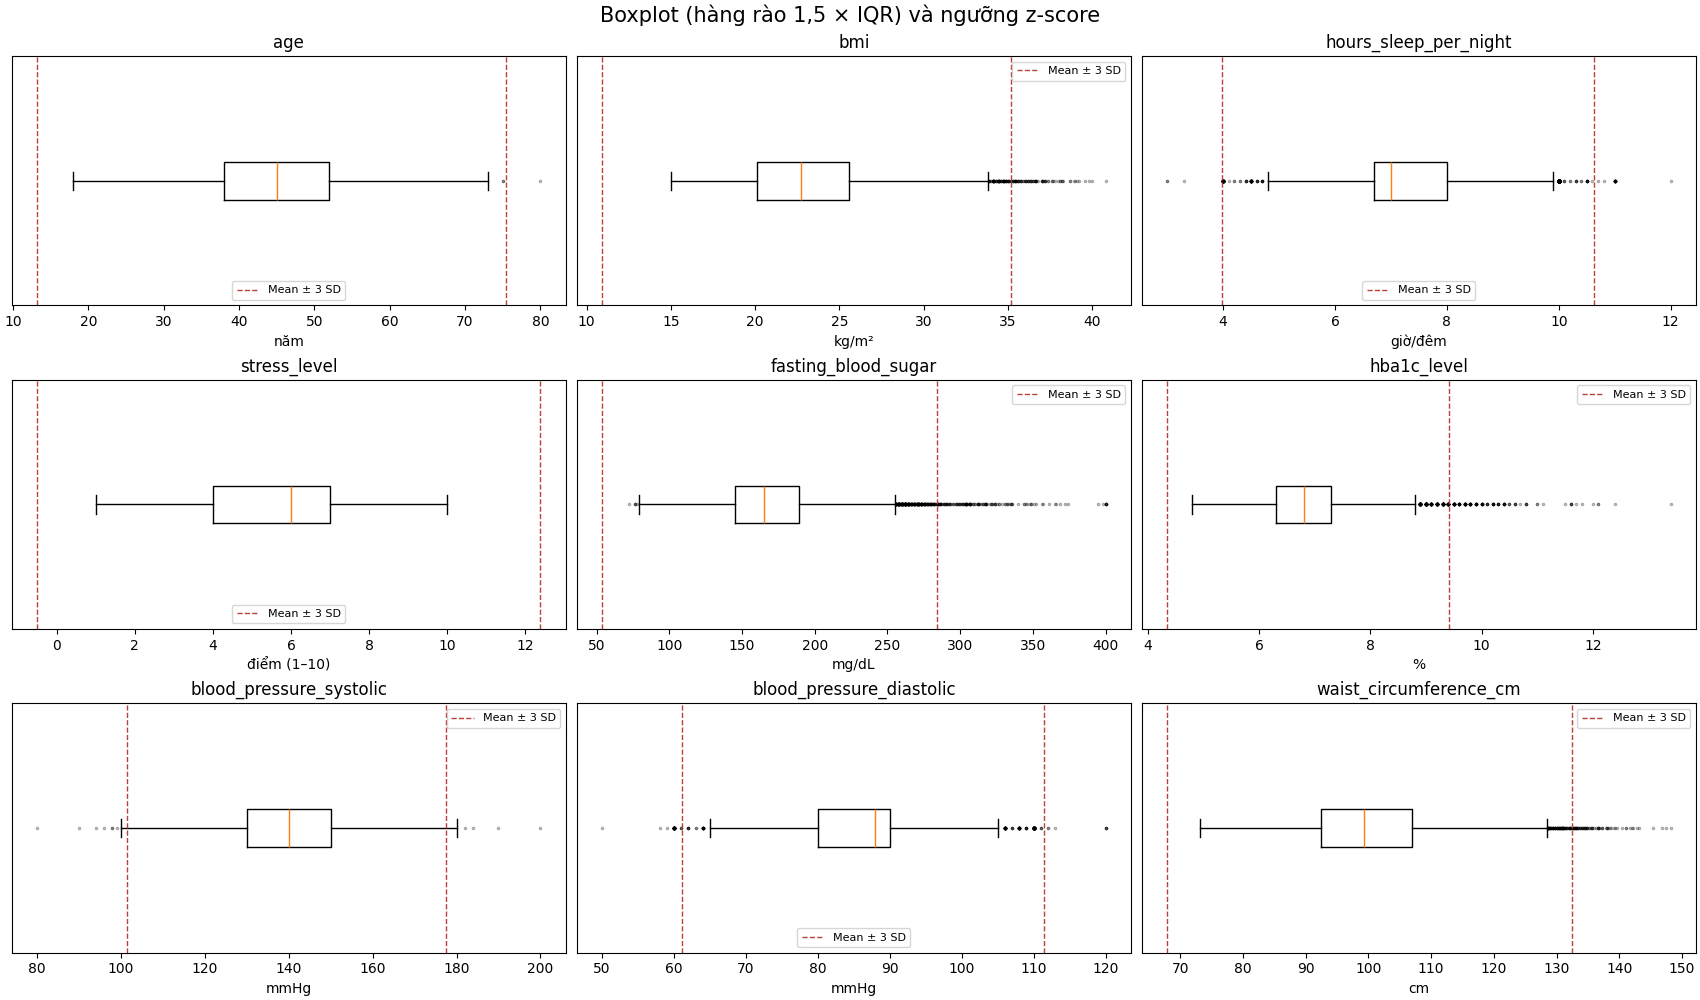

In [8]:
fig = Figure(figsize=(17, 10), layout="constrained")
axes = fig.subplots(3, 3)
for ax, col in zip(axes.flat, numeric_cols):
    ax.boxplot(numeric_df[col].dropna(), vert=False, whis=1.5,
               flierprops={"marker": ".", "markersize": 3, "alpha": 0.35})
    ax.axvline(outlier_summary.loc[col, "z_lower"], color="#bc3f36",
               linestyle="--", linewidth=1, label="Mean ± 3 SD")
    ax.axvline(outlier_summary.loc[col, "z_upper"], color="#bc3f36", linestyle="--", linewidth=1)
    ax.set(title=col, xlabel=units[col], yticks=[])
    ax.legend(fontsize=8)
fig.suptitle("Boxplot (hàng rào 1,5 × IQR) và ngưỡng z-score", fontsize=15)
display_figure(fig)

In [9]:
# Bảng dài giữ đầy đủ mọi cặp (hồ sơ, biến) bị một trong hai phương pháp gắn cờ.
flagged_pairs = union_flags.stack()
flagged_pairs = flagged_pairs[flagged_pairs].index
outlier_details = pd.DataFrame([
    {
        "row_index": row, "patient_id": df.at[row, "patient_id"], "cot": col,
        "gia_tri": df.at[row, col], "z_score": z_scores.at[row, col],
        "IQR_flag": bool(iqr_flags.at[row, col]), "z_flag": bool(z_flags.at[row, col]),
        "ngoai_mien_nguon": bool(source_violation.at[row, col]),
        "diabetes_risk": df.at[row, "diabetes_risk"],
    }
    for row, col in flagged_pairs
], columns=["row_index", "patient_id", "cot", "gia_tri", "z_score", "IQR_flag",
            "z_flag", "ngoai_mien_nguon", "diabetes_risk"])
# In tối đa 2 điểm có |z| lớn nhất mỗi biến; toàn bộ vẫn ở outlier_details.
review_examples = (
    outlier_details.assign(abs_z=lambda x: x["z_score"].abs())
    .sort_values("abs_z", ascending=False)
    .groupby("cot", sort=False).head(2).sort_values(["cot", "abs_z"], ascending=[True, False])
)
display(review_examples.round(3))
print(f"Bảng outlier_details lưu {len(outlier_details):,} cặp hồ sơ–biến để truy vết.")

Bảng outlier_details lưu 1,739 cặp hồ sơ–biến để truy vết.


,row_index,patient_id,cot,gia_tri,z_score,IQR_flag,z_flag,ngoai_mien_nguon,diabetes_risk,abs_z
112,843,844,age,80.0,3.435,True,True,False,High,3.435
1118,9688,9689,age,75.0,2.953,True,False,False,High,2.953
1708,14715,14716,blood_pressure_diastolic,50.0,-4.323,True,True,False,Moderate,4.323
66,553,554,blood_pressure_diastolic,120.0,4.024,True,True,False,Moderate,4.024
1506,12906,12907,blood_pressure_systolic,200.0,4.779,True,True,False,Low,4.779
3,31,32,blood_pressure_systolic,80.0,-4.699,True,True,False,Low,4.699
482,4438,4439,bmi,40.8,4.384,True,True,False,High,4.384
1087,9538,9539,bmi,40.0,4.186,True,True,False,Low,4.186
1340,11532,11533,fasting_blood_sugar,400.0,6.027,True,True,False,High,6.027
10,105,106,fasting_blood_sugar,400.0,6.027,True,True,False,High,6.027


### Kết quả và đánh giá nguyên nhân

| Biến | Số cờ IQR | Số cờ z-score | Đánh giá theo mã sinh và dữ liệu |
| --- | ---: | ---: | --- |
| Tuổi | 3 | 1 | Các tuổi cao hiếm trong mẫu nhưng vẫn trong 18–95; không có bằng chứng lỗi. |
| BMI | 153 | 82 | Đuôi phải của log-normal; cực trị còn trong miền 15–60. Giữ lại. |
| Giờ ngủ | 360 | 22 | Tập trung tại 7–8 giờ làm IQR hẹp; đầu 3/12 giờ hiếm nhưng thuộc thiết kế. |
| Stress | 0 | 0 | Tất cả đúng thang 1–10. |
| Đường huyết lúc đói | 432 | 151 | Có cả cờ thấp và cao; đuôi mũ được chủ động thêm, 6 điểm 400 bị chặn. Giữ và ghi nhận hiệu ứng chặn cận. |
| HbA1c | 355 | 142 | Đuôi cao liên quan đường huyết và nhiễu; không phải tự thân là lỗi. |
| Huyết áp tâm thu | 11 | 56 | IQR = 20 trong dữ liệu có làm tròn khiến hàng rào 100–180 rộng hơn mean ± 3 SD (101,52–177,48); z-score gắn nhiều cờ hơn. |
| Huyết áp tâm trương | 213 | 57 | Miền IQR 65–105 hẹp hơn ngưỡng z; cần kiểm tra quan hệ với tâm thu thay vì chỉ nhìn cờ đơn biến. |
| Vòng eo | 167 | 80 | Đuôi phải đi cùng BMI, nhiễu tăng theo BMI; có cơ chế sinh giải thích được. |

Theo dòng duy nhất, **1.239 hồ sơ** có cờ IQR (8,26%), **437** có cờ z-score (2,91%), và hợp hai phương pháp là **1.279** (8,53%). Khác biệt giữa hai phương pháp phản ánh hình dáng phân phối và làm tròn; không có yêu cầu chúng phải trùng nhau.

Vì nguồn là **synthetic**, không thể gọi các điểm này là bệnh nhân thật đã được xác minh. Phân loại phù hợp là **giá trị mô phỏng có cơ chế giải thích được**, **giá trị bị chặn cận**, hoặc **bất nhất cần kiểm tra**. Không có bằng chứng để xóa toàn bộ 1.279 hồ sơ. Kiểm tra đơn biến cũng không thay thế kiểm tra logic giữa các biến ở mục tiếp theo.

## 9. Rà soát giá trị vô lý và placeholder

Kiểm tra trực tiếp cả `df` và chuỗi gốc đọc bằng `keep_default_na=False` để phân biệt ô trống với các token bị pandas tự hiểu là thiếu. Rà soát số âm/0 không hợp lệ, NaN/±∞, kiểu số và số nguyên, miền mã sinh, mã định danh, miền danh mục, chuỗi trống/khoảng trắng và các token như `999`, `-1`, `N/A`, `unknown`.

Một token giống placeholder **chưa đủ chứng minh là lỗi**: `patient_id=999` là mã hợp lệ; các giá trị `99` trong huyết áp/đường huyết cũng không được coi là thiếu hàng loạt. `Never` là câu trả lời hợp lệ, khác với ô trống. Danh sách token là quy tắc sàng lọc công khai, không bảo đảm phát hiện mọi cách mã hóa thiếu có thể tồn tại.

In [10]:
raw_text = pd.read_csv(data_path, dtype=str, keep_default_na=False)
number_cols = ["patient_id", *numeric_cols]
candidate_numbers = {0, -1, -9, -99, -999, -9999, 999, 9999, 99999}
candidate_words = {"na", "n/a", "nan", "null", "none", "unknown", "missing", "?", "-"}
placeholder_rows = []
for col in raw_text:
    stripped = raw_text[col].str.strip()
    numeric_token = pd.to_numeric(stripped, errors="coerce").isin(candidate_numbers)
    word_token = stripped.str.casefold().isin(candidate_words)
    for row in raw_text.index[numeric_token | word_token]:
        token = raw_text.at[row, col]
        # Mã sinh dùng dãy 1..n; chỉ chấp nhận token nguyên trong miền định danh.
        parsed_token = pd.to_numeric(token, errors="coerce")
        legitimate_id = (col == "patient_id" and pd.notna(parsed_token)
                         and float(parsed_token).is_integer()
                         and 1 <= parsed_token <= len(df))
        placeholder_rows.append({
            "patient_id": df.at[row, "patient_id"], "cot": col, "token": token,
            "danh_gia": "Mã định danh hợp lệ" if legitimate_id else "Cần kiểm tra ngữ cảnh",
        })
placeholder_candidates = pd.DataFrame(
    placeholder_rows, columns=["patient_id", "cot", "token", "danh_gia"]
)
display(placeholder_candidates)

raw_quality = pd.DataFrame({
    "so_o_thieu_pandas": df.isna().sum(),
    "so_chuoi_rong_hoac_chi_khoang_trang": raw_text.apply(lambda s: s.str.strip().eq("").sum()),
    "so_chuoi_co_khoang_trang_dau_cuoi": raw_text.apply(lambda s: s.ne(s.str.strip()).sum()),
})
display(raw_quality)

,patient_id,cot,token,danh_gia
0,999,patient_id,999,Mã định danh hợp lệ
1,9999,patient_id,9999,Mã định danh hợp lệ


,so_o_thieu_pandas,so_chuoi_rong_hoac_chi_khoang_trang,so_chuoi_co_khoang_trang_dau_cuoi
patient_id,0,0,0
age,0,0,0
gender,0,0,0
city,0,0,0
bmi,0,0,0
family_history_diabetes,0,0,0
physical_activity_level,0,0,0
diet_type,0,0,0
smoking_status,472,472,0
alcohol_consumption,3788,3788,0


In [11]:
allowed_categories = {
    "gender": {"Male", "Female", "Other"},
    "city": {"Mumbai", "Delhi", "Bengaluru", "Hyderabad", "Ahmedabad", "Chennai",
             "Kolkata", "Surat", "Pune", "Jaipur", "Lucknow", "Kanpur", "Nagpur",
             "Indore", "Thane", "Bhopal", "Visakhapatnam", "Patna"},
    "family_history_diabetes": {"Yes", "No"},
    "physical_activity_level": {"Sedentary", "Moderate", "Active"},
    "diet_type": {"Vegetarian", "Non-Vegetarian", "Vegan", "Pescatarian"},
    "smoking_status": {"Never", "Current", "Former"},
    "alcohol_consumption": {"Never", "Occasional", "Regular"},
    "income_bracket": {"Low", "Middle", "High"},
    "diabetes_risk": {"Low", "Moderate", "High"},
}
quality_flags = pd.DataFrame(index=df.index)
for col in number_cols:
    parsed = pd.to_numeric(raw_text[col].str.strip(), errors="coerce")
    quality_flags[f"{col}: thieu_hoac_khong_huu_han"] = ~np.isfinite(parsed)
    quality_flags[f"{col}: khong_duong"] = parsed.le(0)
integer_cols = ["patient_id", "age", "stress_level", "fasting_blood_sugar",
                "blood_pressure_systolic", "blood_pressure_diastolic"]
for col in integer_cols:
    parsed = pd.to_numeric(raw_text[col].str.strip(), errors="coerce")
    quality_flags[f"{col}: khong_nguyen"] = np.isfinite(parsed) & parsed.mod(1).ne(0)
for col in numeric_cols:
    quality_flags[f"{col}: ngoai_mien_ma_sinh"] = source_violation[col]
for col, allowed in allowed_categories.items():
    quality_flags[f"{col}: danh_muc_la"] = df[col].notna() & ~df[col].isin(allowed)

# Thiếu chỉ được thiết kế tại ba cột này; các cột khác cần có thông tin.
optional_cols = {"smoking_status", "income_bracket", "alcohol_consumption"}
for col in allowed_categories.keys() - optional_cols:
    quality_flags[f"{col}: thieu_ngoai_thiet_ke"] = df[col].isna()
quality_flags["patient_id: ngoai_mien_1_den_n"] = ~df["patient_id"].between(1, len(df))
quality_flags["patient_id: trung_lap"] = df["patient_id"].duplicated(keep=False)
quality_flags["ho_so_trung_khong_tinh_id"] = df.drop(columns="patient_id").duplicated(keep=False)
quality_flags["ban_ghi_trung_hoan_toan"] = df.duplicated(keep=False)
bp_conflict = df["blood_pressure_diastolic"].ge(df["blood_pressure_systolic"])
quality_flags["huyet_ap: tam_truong_ge_tam_thu"] = bp_conflict

quality_summary = quality_flags.sum().rename("so_ho_so").to_frame()
quality_summary["ty_le_%"] = quality_summary["so_ho_so"] / len(df) * 100
print(f"Đã kiểm tra {quality_flags.shape[1]} quy tắc; dưới đây là các quy tắc có phát hiện:")
display(quality_summary.loc[quality_summary["so_ho_so"].gt(0)].round(4))
display(df.loc[bp_conflict, ["patient_id", "age", "bmi", "blood_pressure_systolic",
                            "blood_pressure_diastolic", "diabetes_risk"]])

# Giữ riêng cờ thống kê và cờ chất lượng để dùng ở notebook tiền xử lý.
review_flags = pd.DataFrame({
    "patient_id": df["patient_id"], "outlier_IQR": iqr_flags.any(axis=1),
    "outlier_z": z_flags.any(axis=1), "can_ra_soat_chat_luong": quality_flags.any(axis=1),
    "bat_nhat_huyet_ap": bp_conflict,
})
print(f"Tổng hồ sơ có cờ chất lượng: {review_flags['can_ra_soat_chat_luong'].sum():,}")
print("Các bảng cờ được giữ trong bộ nhớ; CSV gốc và df không bị thay đổi.")

Đã kiểm tra 55 quy tắc; dưới đây là các quy tắc có phát hiện:
Tổng hồ sơ có cờ chất lượng: 2
Các bảng cờ được giữ trong bộ nhớ; CSV gốc và df không bị thay đổi.


,so_ho_so,ty_le_%
huyet_ap: tam_truong_ge_tam_thu,2,0.0133


,patient_id,age,bmi,blood_pressure_systolic,blood_pressure_diastolic,diabetes_risk
4376,4377,30,21.8,100,100,Low
6729,6730,22,19.8,90,100,Low


### Kết luận rà soát và hướng xử lý

- **Không phát hiện** tuổi âm, số đo ≤0, giá trị số không hữu hạn/thiếu, số lẻ ở cột quy định số nguyên, giá trị vượt miền mã sinh, danh mục lạ, mã bệnh nhân ngoài 1–15.000, mã bệnh nhân trùng, bản ghi trùng hoàn toàn hay hồ sơ trùng khi bỏ mã định danh. Không phát hiện token placeholder đáng ngờ ngoài các mã định danh hợp lệ `999` và `9999`.
- **4.723 ô trống** gồm 472 ở hút thuốc, 463 ở thu nhập và 3.788 ở rượu bia; khớp giá trị thiếu đã báo cáo. Đây là thiếu theo thiết kế, không phải lý do để đổi thành `Never` hay 0. Không có chuỗi thừa khoảng trắng đầu/cuối.
- **2 hồ sơ bất nhất huyết áp:** `patient_id=4377` có **100/100**, `patient_id=6730` có **90/100** mmHg, chiếm **0,0133%** mẫu. American Heart Association [7] giải thích tâm thu là số cao hơn và tâm trương là số thấp hơn. Đây là cờ logic cần ưu tiên, ngay cả khi từng giá trị riêng vẫn trong miền.
- Mã sinh tạo hai số huyết áp bằng hai công thức và nhiễu riêng, sau đó làm tròn/chặn từng cột, **không ràng buộc tâm thu > tâm trương**. Do CSV khớp bản nguồn, bằng chứng ủng hộ **bất nhất của cơ chế mô phỏng và biểu diễn**, chưa có cơ sở quy cho lỗi chép/đọc CSV. Tái chạy mã sinh cho thấy hồ sơ 4377 có cặp trước làm tròn khoảng 101,38/95,90 (tâm thu vẫn cao hơn), sau làm tròn thành 100/100; hồ sơ 6730 đã đảo thứ tự ngay trước làm tròn, khoảng 93,41/95,30, rồi thành 90/100. Vì vậy, hai dòng đều cần gắn cờ nhưng không có cùng nguyên nhân trực tiếp. Không tự hoán đổi hai số hoặc đoán số đúng.

**Quyết định cho bước tiếp theo:** giữ nguyên dữ liệu thô; giữ các ngoại lai có cơ chế sinh hợp lý và lưu cờ `review_flags`/`outlier_details`. Với 2 cặp huyết áp, giữ cờ bất nhất; nếu cần bản sạch thì tạo bản sao và đặt hai số đo của các dòng này thành thiếu, ghi nhật ký, rồi so sánh độ nhạy với phương án giữ nguyên. Chưa thực hiện sửa/xóa trong notebook khám phá. Nếu điền thiếu, chuẩn hóa hoặc đặt ngưỡng ngoại lai cho mô hình, chỉ ước lượng tham số trên tập train sau khi chia dữ liệu để tránh rò rỉ thông tin.

Không có hồ sơ bệnh nhân thực để xác minh các cực trị; các kết luận ở đây giới hạn ở tính nhất quán của CSV, logic số đo và mã sinh dữ liệu tổng hợp.

## 10. Kiểm chứng độc lập sau rà soát

Ngày 31/10/2026, đọc lại CSV bằng thư viện chuẩn `csv`, tính phân vị bằng `statistics.quantiles(method="inclusive")` (tương đương nội suy tuyến tính), tính mean/median/SD và skewness bằng công thức độc lập, rồi đối chiếu toàn bộ cờ IQR/z-score theo từng dòng. Ô dưới phát sinh lỗi nếu kết quả không khớp các bảng phân tích.

Đối chiếu mã nguồn còn cho thấy **đúng tại cận không có nghĩa là chắc chắn bị chặn**: tuổi 18 gồm cả chặn và làm tròn; BMI 15,0 cũng gồm hai cơ chế. Hai cặp huyết áp không hợp logic lần lượt liên quan đến mất chênh lệch do làm tròn và sự đảo thứ tự có sẵn trước làm tròn. Những điểm này đã được chỉnh trong nhận xét phía trên.

Đơn vị và ngưỡng xét nghiệm chỉ được dùng để đặt số liệu vào bối cảnh. Theo NIDDK [6], các mốc đường huyết lúc đói 126 mg/dL và HbA1c 6,5% cần được diễn giải trong quy trình xét nghiệm xác nhận. Trong mẫu mô phỏng, **13.092/15.000 (87,28%)** có đường huyết ≥126 và **10.346/15.000 (68,97%)** có HbA1c ≥6,5%; ngay nhóm nhãn `Low` cũng có **7.093/9.000 (78,81%)** vượt mốc đường huyết này. Đây là bằng chứng cụ thể rằng `Low` là mức tương đối của điểm mô phỏng, không thể diễn giải là đường huyết bình thường hay chưa mắc bệnh; các tỷ lệ trên không phải tỷ lệ mắc bệnh thực tế.

Mã sinh đã đối chiếu: `generate_dataset.py`, Kaggle phiên bản 1 [3]; SHA-256 `b8ab64d71e0895af8703bb0bba2422ece9bd119eea95b396f482e01e1252c75d`. Phần tái sinh và truy vết trước chặn/làm tròn được kiểm tra riêng với seed 42; các bảng phân tích và ô đối chiếu bên dưới chạy hoàn toàn từ CSV cục bộ.

In [12]:
import csv
import statistics

with data_path.open(encoding="utf-8", newline="") as handle:
    independent_rows = list(csv.DictReader(handle))
audit_rows = []
for col in numeric_cols:
    values = np.array([float(row[col]) for row in independent_rows])
    a_q1, _, a_q3 = statistics.quantiles(values.tolist(), n=4, method="inclusive")
    a_mean = statistics.mean(values.tolist())
    a_sd = statistics.stdev(values.tolist())
    n = len(values)
    a_skew = n / ((n - 1) * (n - 2)) * np.sum(((values - a_mean) / a_sd) ** 3)
    a_modes = statistics.multimode(values.tolist())
    expected_stats = [values.min(), a_q1, statistics.median(values.tolist()), a_mean,
                      a_q3, values.max(), a_sd, a_q3 - a_q1, a_skew]
    reported_stats = summary.loc[col, ["min", "Q1", "median", "mean", "Q3", "max",
                                       "std", "IQR", "skewness"]].to_numpy(dtype=float)
    np.testing.assert_allclose(expected_stats, reported_stats, rtol=1e-12, atol=1e-12)
    assert set(a_modes) == set(numeric_df[col].mode())
    a_lower = round(a_q1 - 1.5 * (a_q3 - a_q1), 10)
    a_upper = round(a_q3 + 1.5 * (a_q3 - a_q1), 10)
    a_iqr = (values < a_lower) | (values > a_upper)
    a_z = np.abs((values - a_mean) / statistics.pstdev(values.tolist())) > 3
    np.testing.assert_array_equal(a_iqr, iqr_flags[col].to_numpy())
    np.testing.assert_array_equal(a_z, z_flags[col].to_numpy())
    audit_rows.append({"cot": col, "thong_ke_khop": True,
                       "IQR_n_doc_lap": int(a_iqr.sum()), "z_n_doc_lap": int(a_z.sum())})
assert df["patient_id"].tolist() == list(range(1, len(df) + 1))
assert len(outlier_details) == int(union_flags.to_numpy().sum())
assert df.loc[bp_conflict, "patient_id"].tolist() == [4377, 6730]
display(pd.DataFrame(audit_rows).set_index("cot"))
print("Đối chiếu độc lập: thống kê và toàn bộ cờ theo dòng đều khớp.")
print(f"Hồ sơ duy nhất: IQR={iqr_flags.any(axis=1).sum():,}; "
      f"z-score={z_flags.any(axis=1).sum():,}; hợp={union_flags.any(axis=1).sum():,}.")
print(f"SHA-256 CSV: {hashlib.sha256(data_path.read_bytes()).hexdigest()}")

Đối chiếu độc lập: thống kê và toàn bộ cờ theo dòng đều khớp.
Hồ sơ duy nhất: IQR=1,239; z-score=437; hợp=1,279.
SHA-256 CSV: 1d4ea5e5dfb63ce2622a578736e6a31a330731a7daa8fc93c3987d7c7c119220


,thong_ke_khop,IQR_n_doc_lap,z_n_doc_lap
cot,,,
age,True,3,1
bmi,True,153,82
hours_sleep_per_night,True,360,22
stress_level,True,0,0
fasting_blood_sugar,True,432,151
hba1c_level,True,355,142
blood_pressure_systolic,True,11,56
blood_pressure_diastolic,True,213,57
waist_circumference_cm,True,167,80


## 11. Tài liệu tham khảo

Các số trong ngoặc vuông ở nội dung tương ứng với các nguồn dưới đây.

- [1] Mansi Aggarwal. *Diabetes Risk Prediction — metadata API*. Kaggle. Thông tin tác giả, phiên bản, ngày phát hành, dữ liệu tổng hợp và giấy phép. Kiểm tra ngày 28/10/2026. [Đường dẫn nguồn](https://www.kaggle.com/api/v1/datasets/view/mansiaggarwal88/diabetes-risk-prediction)

- [2] Aggarwal, M. (2026). *Diabetes Risk Prediction* (Version 1) [Bộ dữ liệu tổng hợp]. Kaggle. CC0 1.0 Universal. Truy cập ngày 28/10/2026. [Đường dẫn nguồn](https://www.kaggle.com/datasets/mansiaggarwal88/diabetes-risk-prediction)

- [3] Mansi Aggarwal. *Gói dữ liệu Diabetes Risk Prediction, phiên bản 1*. Kaggle. Gồm `diabetes_risk.csv` và `generate_dataset.py`. Đối chiếu ban đầu ngày 28/10/2026; kiểm tra lại mã sinh và dữ liệu ngày 31/10/2026. [Đường dẫn nguồn](https://www.kaggle.com/api/v1/datasets/download/mansiaggarwal88/diabetes-risk-prediction?datasetVersionNumber=1)

- [4] Creative Commons. *CC0 1.0 Universal*. Nội dung giấy phép và phạm vi từ bỏ quyền tác giả. Kiểm tra ngày 28/10/2026. [Đường dẫn nguồn](https://creativecommons.org/publicdomain/zero/1.0/)

- [5] Centers for Disease Control and Prevention (CDC). *Adult BMI Categories*. Phân nhóm BMI cho người từ 20 tuổi. Kiểm tra ngày 31/10/2026. [Đường dẫn nguồn](https://www.cdc.gov/bmi/adult-calculator/bmi-categories.html)

- [6] National Institute of Diabetes and Digestive and Kidney Diseases (NIDDK). *Diabetes Tests & Diagnosis*. Ngưỡng xét nghiệm đường huyết lúc đói, HbA1c và yêu cầu xác nhận kết quả. Kiểm tra ngày 31/10/2026. [Đường dẫn nguồn](https://www.niddk.nih.gov/health-information/diabetes/overview/tests-diagnosis)

- [7] American Heart Association. *Life’s Simple 7 — Blood Pressure*. Giải thích huyết áp tâm thu và tâm trương. Kiểm tra ngày 31/10/2026. [Đường dẫn nguồn](https://www.heart.org/-/media/files/professional/workplace-health/lifes-simple-7/ls7_blood-pressure.pdf)